In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, TensorDataset
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import torchvision.datasets as datasets

In [2]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.fc(x)


In [3]:
transform = transforms.Compose([transforms.ToTensor()])
dataset = datasets.MNIST(root='data', train=True, download=True, transform=transform)
testset = datasets.MNIST(root='data', train=False, download=True, transform=transform)

num_clients = 5
client_sizes = [len(dataset)//num_clients]*num_clients
client_datasets = random_split(dataset, client_sizes)

client_loaders = [DataLoader(ds, batch_size=64, shuffle=True) for ds in client_datasets]
test_loader = DataLoader(testset, batch_size=1000, shuffle=False)


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 495kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.1MB/s]


In [4]:
def local_train(model, train_loader, epochs=1):
    optimizer = optim.SGD(model.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()
    model.train()
    for _ in range(epochs):
        for data, target in train_loader:
            optimizer.zero_grad()
            output = model(data.view(data.size(0), -1))
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
    return model.state_dict()


In [5]:
def fed_avg(state_dicts):
    avg_state = {}
    for key in state_dicts[0].keys():
        avg_state[key] = sum(state_dict[key] for state_dict in state_dicts) / len(state_dicts)
    return avg_state


In [6]:
def evaluate(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    loss_total = 0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for data, target in test_loader:
            outputs = model(data.view(data.size(0), -1))
            loss = criterion(outputs, target)
            loss_total += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()
    accuracy = 100 * correct / total
    avg_loss = loss_total / len(test_loader)
    return accuracy, avg_loss

In [7]:
global_model = Net()
rounds = 5
global_acc = []
global_loss = []

for r in range(rounds):
    print(f"\n Round {r+1} / {rounds}")
    local_states = []
    for i, loader in enumerate(client_loaders):
        local_model = Net()
        local_model.load_state_dict(global_model.state_dict())
        local_state = local_train(local_model, loader, epochs=1)
        local_states.append(local_state)
        print(f"Client {i+1} trained locally.")

    global_model.load_state_dict(fed_avg(local_states))

    acc, loss = evaluate(global_model, test_loader)
    global_acc.append(acc)
    global_loss.append(loss)
    print(f" Round {r+1}: Test Accuracy = {acc:.2f}%, Loss = {loss:.4f}")


 Round 1 / 5
Client 1 trained locally.
Client 2 trained locally.
Client 3 trained locally.
Client 4 trained locally.
Client 5 trained locally.
 Round 1: Test Accuracy = 69.87%, Loss = 1.8729

 Round 2 / 5
Client 1 trained locally.
Client 2 trained locally.
Client 3 trained locally.
Client 4 trained locally.
Client 5 trained locally.
 Round 2: Test Accuracy = 79.42%, Loss = 1.2542

 Round 3 / 5
Client 1 trained locally.
Client 2 trained locally.
Client 3 trained locally.
Client 4 trained locally.
Client 5 trained locally.
 Round 3: Test Accuracy = 83.49%, Loss = 0.8680

 Round 4 / 5
Client 1 trained locally.
Client 2 trained locally.
Client 3 trained locally.
Client 4 trained locally.
Client 5 trained locally.
 Round 4: Test Accuracy = 85.60%, Loss = 0.6818

 Round 5 / 5
Client 1 trained locally.
Client 2 trained locally.
Client 3 trained locally.
Client 4 trained locally.
Client 5 trained locally.
 Round 5: Test Accuracy = 86.75%, Loss = 0.5800


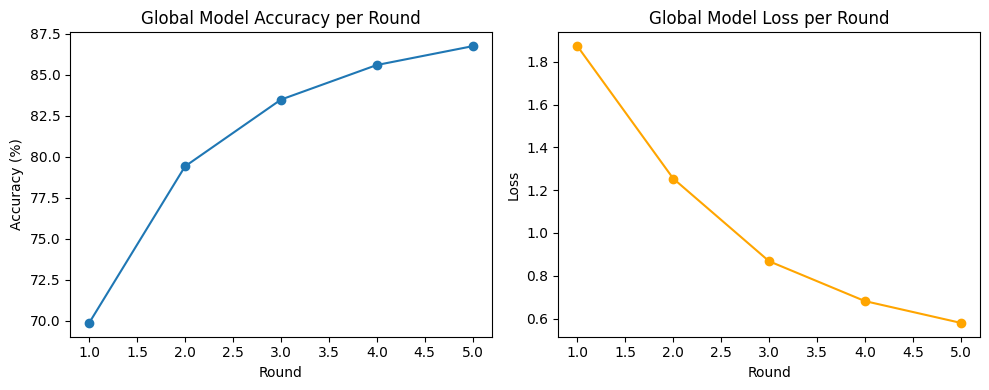

In [8]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(range(1, rounds+1), global_acc, marker='o')
plt.title("Global Model Accuracy per Round")
plt.xlabel("Round")
plt.ylabel("Accuracy (%)")

plt.subplot(1,2,2)
plt.plot(range(1, rounds+1), global_loss, marker='o', color='orange')
plt.title("Global Model Loss per Round")
plt.xlabel("Round")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()